# Lab 1: Multi-Class Feed-Forward Neural Network Using PyTorch

**Albert Kabore**, PhD student in Artificial Intelligence<br>
October 28, 2026

Part A explains the classifier implemented in this lab. Part B contains the complete
PyTorch implementation, its outputs, and observations using the local AG News CSV files.
Part C explains the commands and interprets the measured results. The implementation adapts
the chapter 7 reference notebook by Surdeanu and Valenzuela-Escárcega (2023); sources are
cited throughout and listed at the end.


## Part A: Feed-Forward Neural Networks

A feed-forward neural network passes information from input to output through successive
layers without recurrent connections. Here, its inputs are bag-of-words features: token
frequencies representing each news article. This implementation adapts Surdeanu and
Valenzuela-Escárcega (2023) and uses AG News,
which contains 120,000 training articles and 7,600 test articles in four categories: World,
Sports, Business, and Sci/Tech (Zhang et al., 2015).

Pandas loads each article's class index, title, and description. The local CSV files have
headers. The title and description are joined and lowercased. Pandas replaces backslashes
with spaces; additional cleaning decodes HTML character references, removes tags and URLs,
and replaces corrupted `#NAME?` fields with empty strings. NLTK's `word_tokenize()` splits
the combined text into tokens, stored in a new dataframe column (Bird et al., 2009).

An 80/20 split reserves 24,000 training-file articles for development and leaves 96,000 for
fitting the model. The vocabulary is learned exclusively from this fitting split. Tokens
occurring more than ten times receive individual integer identifiers; all other tokens map
to `[UNK]`. Each document becomes a 17,369-dimensional vector with one position per vocabulary
entry. Each value counts that token's occurrences; absent tokens have value zero. This
representation retains frequency but discards word order and provides no explicit
representation of synonymy.
Sparse dictionaries store the counts, and a PyTorch `Dataset` creates dense float32 vectors
as batches are requested.

The network applies input dropout, a linear layer with 50 hidden units, ReLU, hidden dropout,
and a linear layer producing four logits, or unnormalized class scores. The hidden layer
learns weighted combinations of token counts. ReLU introduces nonlinearity; dropout randomly
zeros inputs and hidden activations with probability 0.3 during training to reduce overfitting
(Goodfellow et al., 2016; Srivastava et al., 2014).

Training uses shuffled batches of 500 for five epochs. `CrossEntropyLoss` takes the logits
and zero-based integer labels, combining log-softmax with negative log-likelihood. An
additional softmax layer is unnecessary. Adam updates the parameters using learning rate
0.001 and weight decay 0.00001 (Kingma & Ba, 2015). Each step clears gradients, computes
predictions and loss, backpropagates, and updates the weights.

Development loss and accuracy monitor learning without updating parameters. After training,
the test set receives identical cleaning, tokenization, and encoding with the fixed training
vocabulary. `model.eval()` disables dropout, and `torch.no_grad()` disables gradient tracking.
The largest logit determines the predicted class. Accuracy, per-class precision, recall, F1,
and a confusion matrix quantify performance and show which topics are confused.


---
## Part B: Model Implementation

### B.1 Initialization and tqdm in pandas

In [1]:
import random
import time

run_started = time.perf_counter()

import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

# enable tqdm in pandas (adds .progress_map / .progress_apply)
tqdm.pandas()

# use the GPU if one is available
use_gpu = True
device = torch.device('cuda' if use_gpu and torch.cuda.is_available() else 'cpu')
print(f'device: {device.type}')

# seed the random generators; hardware/library differences can still affect results
seed = 1234
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
print(f'random seed: {seed}')
print(f'PyTorch threads: {torch.get_num_threads()}')

device: cpu
random seed: 1234
PyTorch threads: 8


#### Observations (B.1)

- This run uses the CPU because CUDA is unavailable.
- Seed 1234 controls the random split, initialization, dropout, and batch sampling.
  Reproducibility also depends on library versions, hardware, and deterministic operations;
  a fixed seed alone does not guarantee identical results across environments (PyTorch, n.d.).


### B.2 The AG's News Topic Classification Dataset

The data is in `data/ag_news_csv/`: `train.csv`, `test.csv`, and `classes.txt`, which lists
the class names in label order.

**Source and verification.** The local CSV files use the headered Kaggle variant of
*AG News Classification Dataset* (Anand, 2020). The original release by Zhang et al. (2015)
is also distributed through fast.ai and includes `classes.txt`. A direct comparison with
that archive confirms identical labels in every row and identical class names. Text differs
in 26 training rows and 2 test rows. The recorded comparison is saved in
`artifacts/data_comparison.json`; B.3 describes the local text corruption.


In [2]:
from pathlib import Path

data_dir = Path('data/ag_news_csv')
for name in ['train.csv', 'test.csv', 'classes.txt']:
    path = data_dir / name
    print(f'{name:12} {path.stat().st_size / 1e6:6.2f} MB')

labels = (data_dir / 'classes.txt').read_text(encoding='utf-8').splitlines()
print('classes:', labels)

train.csv     29.07 MB
test.csv       1.83 MB
classes.txt    0.00 MB
classes: ['World', 'Sports', 'Business', 'Sci/Tech']


#### Observations (B.2)

- All three files load. `train.csv` (29.07 MB) is about 16 times larger than `test.csv`
  (1.83 MB), in line with 120,000 versus 7,600 articles.
- `classes.txt` gives four labels in index order: World, Sports, Business, Sci/Tech.
- Label meaning depends only on line order in that file.

### B.3 Loading and examining the training data

In [3]:
train_df = pd.read_csv(data_dir / 'train.csv')
train_df.columns = ['class index', 'title', 'description']  # local files have headers
assert train_df.shape == (120000, 3)
assert set(train_df['class index'].unique()) == set(range(1, len(labels) + 1))
train_df

,class index,title,description
0,3,Wall St. Bears Claw Back Into the Black (Reuters),"Reuters - Short-sellers, Wall Street's dwindli..."
1,3,Carlyle Looks Toward Commercial Aerospace (Reu...,Reuters - Private investment firm Carlyle Grou...
2,3,Oil and Economy Cloud Stocks' Outlook (Reuters),Reuters - Soaring crude prices plus worries\ab...
3,3,Iraq Halts Oil Exports from Main Southern Pipe...,Reuters - Authorities have halted oil export\f...
4,3,"Oil prices soar to all-time record, posing new...","AFP - Tearaway world oil prices, toppling reco..."
...,...,...,...
119995,1,Pakistan's Musharraf Says Won't Quit as Army C...,KARACHI (Reuters) - Pakistani President Perve...
119996,2,Renteria signing a top-shelf deal,Red Sox general manager Theo Epstein acknowled...
119997,2,Saban not going to Dolphins yet,The Miami Dolphins will put their courtship of...
119998,2,Today's NFL games,PITTSBURGH at NY GIANTS Time: 1:30 p.m. Line: ...


In [4]:
# class indexes in the file start at 1, so subtract 1 to index the labels list
train_df.insert(1, 'class', train_df['class index'].map(lambda i: labels[i - 1]))
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 4 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   class index  120000 non-null  int64 
 1   class        120000 non-null  object
 2   title        120000 non-null  object
 3   description  120000 non-null  object
dtypes: int64(1), object(3)
memory usage: 3.7+ MB


In [5]:
print('missing values per column:')
print(train_df.isna().sum(), end='\n\n')
print('examples per class:')
print(train_df['class'].value_counts())

missing values per column:
class index    0
class          0
title          0
description    0
dtype: int64

examples per class:
class
Business    30000
Sci/Tech    30000
Sports      30000
World       30000
Name: count, dtype: int64


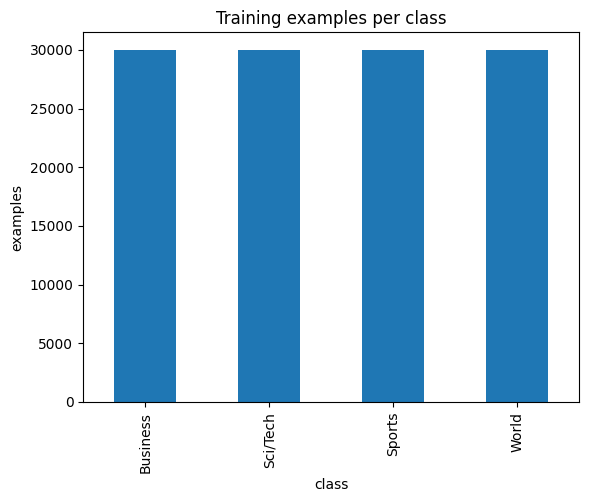

In [6]:
import matplotlib.pyplot as plt

train_df['class'].value_counts().plot.bar(title='Training examples per class')
plt.ylabel('examples')
plt.show()

In [7]:
# length of each field in words
lengths = pd.DataFrame({
    'title words': train_df['title'].str.split().str.len(),
    'description words': train_df['description'].str.split().str.len(),
})
lengths.describe().round(1)

,title words,description words
count,120000.0,120000.0
mean,6.8,31.1
std,2.1,9.8
min,1.0,1.0
25%,5.0,25.0
50%,7.0,30.0
75%,8.0,36.0
max,19.0,173.0


In [8]:
# one sample article per class
train_df.groupby('class').head(1)[['class', 'title', 'description']]

,class,title,description
0,Business,Wall St. Bears Claw Back Into the Black (Reuters),"Reuters - Short-sellers, Wall Street's dwindli..."
78,Sci/Tech,"'Madden,' 'ESPN' Football Score in Different W...",Reuters - Was absenteeism a little high\on Tue...
448,Sports,"Phelps, Thorpe Advance in 200 Freestyle (AP)",AP - Michael Phelps took care of qualifying fo...
492,World,Venezuelans Vote Early in Referendum on Chavez...,Reuters - Venezuelans turned out early\and in ...


In [9]:
raw_text = train_df['title'] + ' ' + train_df['description']

noise_patterns = {
    'backslashes': r'\\',
    'numeric HTML codes (#39;)': r'#\d+;',
    'named HTML codes (quot;, &lt;)': r'(?<!\w)&?(?:lt|gt|quot|amp|nbsp);',
    'URLs': r'https?://|www\.',
    'repeated spaces': r'\s{2,}',
}

def count_noise(text):
    return pd.Series({name: text.str.contains(p, regex=True).sum() for name, p in noise_patterns.items()})

print('rows affected by each kind of noise (out of 120,000):')
print(count_noise(raw_text).to_string(), end='\n\n')
print('cells containing the spreadsheet error #NAME?:')
print((train_df[['title', 'description']] == '#NAME?').sum().to_string(), end='\n\n')
print('duplicate articles:', train_df.duplicated(subset=['title', 'description']).sum())

rows affected by each kind of noise (out of 120,000):


backslashes                       13146
numeric HTML codes (#39;)         31357
named HTML codes (quot;, &lt;)    11226
URLs                               1847
repeated spaces                   20835

cells containing the spreadsheet error #NAME?:
title          15
description     9

duplicate articles: 0


**Description of the dataset.** The training set contains 120,000 news articles. Each row has
a class index from 1 to 4, a headline (`title`), and a short summary (`description`). The four
classes are World, Sports, Business, and Sci/Tech, with exactly 30,000 articles each. Because
the classes are balanced, a classifier that guessed at random would be right about 25% of the
time, and accuracy is a reasonable summary metric. No pandas missing values or exact duplicate title/description pairs were found.
The `#NAME?` strings discussed below are present values but contain corrupted text. The texts are short: the median title has 7 words and the median description
has 30, so the model gets only a few dozen words per article.

The text is not clean, though. About 11% of the rows contain backslashes that stand for line
breaks, and roughly a quarter contain HTML character codes that have lost their leading `&`
(`#39;` is an apostrophe, `#36;` a dollar sign). 1,847 rows contain links, and 96% of those
links sit inside escaped HTML markup. The Kaggle copy also has two problems of its own. First, 15 titles and 9
descriptions contain only `#NAME?`. This is the error value spreadsheet software such as
Microsoft Excel shows when it cannot interpret a formula (Microsoft, n.d.). These placeholders suggest spreadsheet-related corruption, although the local files alone
cannot establish how it happened. The archive comparison confirms that these fields differ
from the original release. Second, two descriptions are cut off at 255
characters. The original text of the `#NAME?` cells is lost in the Kaggle copy, so I replace
them with empty strings and keep the other field of the article. The two shortened
descriptions are left as they are.

#### Observations (B.3)

- 120,000 rows, four columns after adding class names, no pandas missing values, and no exact duplicate title/description pairs.
- The classes are perfectly balanced (30,000 each), so chance accuracy is 25%.
- Texts are short: median title 7 words, median description 30.
- Noise is common: 26% of rows have broken HTML codes, 11% have backslashes, and 24 cells
  hold `#NAME?`.

### B.4 Replacing the backslashes with spaces

The backslashes stand for line breaks in the original articles. The example below shows how one
glues two words together ("dwindling\\band"). I join the title and the description into one
lowercased `text` column and then replace every backslash with a space using the pandas
`replace` method. In `join_fields`, the `#NAME?` cells found in B.3 become empty strings.

In [10]:
print(train_df.loc[0, 'description'])

Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.


In [11]:
def join_fields(df):
    """Title + description; the spreadsheet error '#NAME?' becomes an empty string."""
    title = df['title'].replace('#NAME?', '')
    description = df['description'].replace('#NAME?', '')
    return title + ' ' + description

train_df['text'] = join_fields(train_df).str.lower()

# replace the backslashes with spaces using the pandas replace method
train_df['text'] = train_df['text'].replace(r'\\', ' ', regex=True)

print(train_df.loc[0, 'text'])
print('rows still containing a backslash:', train_df['text'].str.contains('\\', regex=False).sum())

wall st. bears claw back into the black (reuters) reuters - short-sellers, wall street's dwindling band of ultra-cynics, are seeing green again.
rows still containing a backslash: 0


The noise check in B.3 also found broken HTML codes, escaped markup, and links. The next cell
removes them as an extra cleaning step. B.9 applies both steps, in the same order, to the test
set.

In [12]:
import html

def clean_html(text):
    """Decode broken HTML codes and remove tags, URLs, and repeated whitespace."""
    # restore HTML codes that lost their '&' (' #39;' -> '&#39;', 'quot;' -> '&quot;')
    text = text.str.replace(r'(?<!&)#(\d+);', r'&#\1;', regex=True)
    text = text.str.replace(r'(?<![&\w])(quot|amp|lt|gt|nbsp);', r'&\1;', regex=True)
    # decode them; twice, because some text was escaped twice (&amp;apos;)
    text = text.map(lambda s: html.unescape(html.unescape(s)))
    # remove HTML tags and URLs
    text = text.str.replace(r'<[^>]*>', ' ', regex=True)
    text = text.str.replace(r'https?://\S*|www\.\S*', ' ', regex=True)
    # collapse repeated whitespace
    return text.str.replace(r'\s+', ' ', regex=True).str.strip()

train_df['text'] = clean_html(train_df['text'])

In [13]:
# before / after on articles that contained HTML codes
examples = raw_text[raw_text.str.contains(r'#36;|quot;|#39;', regex=True)].index[:3]
for i in examples:
    print('BEFORE:', raw_text[i][:160])
    print('AFTER: ', train_df.loc[i, 'text'][:160], end='\n\n')

print('rows still affected after cleaning:')
print(count_noise(train_df['text']).to_string())
print('#NAME? left:', train_df['text'].str.contains('#name?', regex=False).sum())

BEFORE: Stocks End Up, But Near Year Lows (Reuters) Reuters - Stocks ended slightly higher on Friday\but stayed near lows for the year as oil prices surged past  #36;46
AFTER:  stocks end up, but near year lows (reuters) reuters - stocks ended slightly higher on friday but stayed near lows for the year as oil prices surged past $46 a b

BEFORE: Money Funds Fell in Latest Week (AP) AP - Assets of the nation's retail money market mutual funds fell by  #36;1.17 billion in the latest week to  #36;849.98 tr
AFTER:  money funds fell in latest week (ap) ap - assets of the nation's retail money market mutual funds fell by $1.17 billion in the latest week to $849.98 trillion, 

BEFORE: Safety Net (Forbes.com) Forbes.com - After earning a PH.D. in Sociology, Danny Bazil Riley started to work as the general manager at a commercial real estate fi
AFTER:  safety net (forbes.com) forbes.com - after earning a ph.d. in sociology, danny bazil riley started to work as the general manager at a commercial

backslashes                       0
numeric HTML codes (#39;)         0
named HTML codes (quot;, &lt;)    0
URLs                              0
repeated spaces                   0
#NAME? left: 0


#### Observations (B.4)

- The pandas `replace` step works: "dwindling\band" becomes "dwindling band", and no row
  still contains a backslash.
- HTML decoding restores meaning, for example `#36;46` becomes "$46".
- All noise counts and the `#NAME?` count drop to zero.
- "$849.98 trillion" appears in the source text itself; cleaning did not introduce it.

### B.5 Tokenizing with NLTK's `word_tokenize()`

`word_tokenize()` is applied to the `text` column, which holds the title and description of
each article, and the token lists go into a new `tokens` column. `progress_map` is the tqdm
version of `Series.map`.

In [14]:
import nltk
from nltk.tokenize import word_tokenize

# Reuse installed tokenizer data; download only on the first run.
try:
    nltk.data.find('tokenizers/punkt_tab/english/')
except LookupError:
    nltk.download('punkt_tab', quiet=True, raise_on_error=True)

train_df['tokens'] = train_df['text'].progress_map(word_tokenize)
train_df[['class', 'text', 'tokens']].head()


  0%|          | 0/120000 [00:00<?, ?it/s]

,class,text,tokens
0,Business,wall st. bears claw back into the black (reute...,"[wall, st., bears, claw, back, into, the, blac..."
1,Business,carlyle looks toward commercial aerospace (reu...,"[carlyle, looks, toward, commercial, aerospace..."
2,Business,oil and economy cloud stocks' outlook (reuters...,"[oil, and, economy, cloud, stocks, ', outlook,..."
3,Business,iraq halts oil exports from main southern pipe...,"[iraq, halts, oil, exports, from, main, southe..."
4,Business,"oil prices soar to all-time record, posing new...","[oil, prices, soar, to, all-time, record, ,, p..."


Before building the vocabulary, I hold out 20% of the training data as a development set for
monitoring overfitting. The test set is not touched until B.9.

In [15]:
from sklearn.model_selection import train_test_split

train_df, dev_df = train_test_split(train_df, train_size=0.8, random_state=seed)
train_df = train_df.reset_index(drop=True)
dev_df = dev_df.reset_index(drop=True)

print(f'train rows: {len(train_df):,}')
print(f'dev rows:   {len(dev_df):,}')
print('development class shares:')
print(dev_df['class'].value_counts(normalize=True).reindex(labels).round(4))

train rows: 96,000
dev rows:   24,000
development class shares:
class
World       0.2536
Sports      0.2482
Business    0.2498
Sci/Tech    0.2484
Name: proportion, dtype: float64


#### Observations (B.5)

- `word_tokenize` separates punctuation and quotes: "stocks'" becomes `stocks` and `'`.
- Abbreviations and hyphenated words stay whole, for example `st.` and `all-time`.
- The split is exactly 80/20: 96,000 training rows and 24,000 development rows.
- The test set is still untouched at this point.

### B.6 Creating the vocabulary from the training data

In [16]:
threshold = 10  # keep only tokens seen more than 10 times

token_counts = train_df['tokens'].explode().value_counts()
print(f'distinct tokens before filtering: {len(token_counts):,}')

total_token_occurrences = int(token_counts.sum())
distinct_token_count = len(token_counts)
token_counts = token_counts[token_counts > threshold]
retained_token_occurrences = int(token_counts.sum())
id_to_token = ['[UNK]'] + token_counts.index.tolist()
token_to_id = {token: i for i, token in enumerate(id_to_token)}
vocabulary_size = len(id_to_token)
print(f'vocabulary size: {vocabulary_size:,}')
print('most frequent tokens:', id_to_token[1:21])
print(f'retained token occurrences: {retained_token_occurrences:,} / '
      f'{total_token_occurrences:,} ({retained_token_occurrences / total_token_occurrences:.2%})')

distinct tokens before filtering: 79,175
vocabulary size: 17,369
most frequent tokens: ['the', ',', '.', 'to', 'a', 'of', 'in', 'and', 'on', "'s", 'for', '(', ')', '-', 'that', 'with', 'as', 'at', 'its', 'is']
retained token occurrences: 3,856,145 / 4,010,277 (96.16%)


In [17]:
from collections import defaultdict

def make_feature_vector(tokens, unk_id=0):
    """Sparse bag-of-words: maps token id -> count. Unknown tokens count toward [UNK]."""
    vector = defaultdict(int)
    for t in tokens:
        vector[token_to_id.get(t, unk_id)] += 1
    return vector

train_df['features'] = train_df['tokens'].progress_map(make_feature_vector)
dev_df['features'] = dev_df['tokens'].progress_map(make_feature_vector)

example = train_df.loc[0]
print(example['text'])
print({id_to_token[i]: c for i, c in example['features'].items()})

  0%|          | 0/96000 [00:00<?, ?it/s]

  0%|          | 0/24000 [00:00<?, ?it/s]

najaf's residents feel trapped in battle (ap) ap - for nearly three weeks, amer al-jamali hasn't been able to go to work. he cannot visit his father, find medication for his diabetic children or even sleep on his roof to escape the city's suffocating heat made worse by power outages.
{'najaf': 1, "'s": 2, 'residents': 1, 'feel': 1, 'trapped': 1, 'in': 1, 'battle': 1, '(': 1, 'ap': 2, ')': 1, '-': 1, 'for': 2, 'nearly': 1, 'three': 1, 'weeks': 1, ',': 2, '[UNK]': 4, 'has': 1, "n't": 1, 'been': 1, 'able': 1, 'to': 3, 'go': 1, 'work': 1, '.': 2, 'he': 1, 'can': 1, 'not': 1, 'visit': 1, 'his': 3, 'father': 1, 'find': 1, 'medication': 1, 'children': 1, 'or': 1, 'even': 1, 'sleep': 1, 'on': 1, 'roof': 1, 'escape': 1, 'the': 1, 'city': 1, 'heat': 1, 'made': 1, 'worse': 1, 'by': 1, 'power': 1, 'outages': 1}


#### Observations (B.6)

- Only 17,368 of 79,175 distinct tokens (22%) occur more than 10 times. With `[UNK]` the
  vocabulary has 17,369 entries.
- The top tokens are function words and punctuation. These frequent tokens do not include `#` or `39`; this observation alone does not
  prove that every possible HTML artifact was removed.
- In the example, four rare words (amer, al-jamali, diabetic, suffocating) map to `[UNK]`.

### B.7 Initializing the model, loss function, optimizer, and data loaders

In [18]:
from torch.utils.data import Dataset

class BowDataset(Dataset):
    def __init__(self, x, y):
        self.x = x.reset_index(drop=True)
        self.y = y.reset_index(drop=True)

    def __len__(self):
        return len(self.x)

    def __getitem__(self, index):
        x = torch.zeros(vocabulary_size, dtype=torch.float32)
        for k, v in self.x.iloc[index].items():
            x[k] = v
        y = torch.tensor(self.y.iloc[index], dtype=torch.long)
        return x, y

In [19]:
from torch import nn

class Model(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim, dropout):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, output_dim),
        )

    def forward(self, x):
        return self.layers(x)  # raw scores (logits), one per class

In [20]:
from torch import optim
from torch.utils.data import DataLoader

# hyperparameters (same values as the reference notebook)
lr = 1e-3
weight_decay = 1e-5
batch_size = 500
shuffle = True
n_epochs = 5
input_dim = vocabulary_size
hidden_dim = 50
output_dim = len(labels)
dropout = 0.3

# initialize the model, loss function, optimizer, and data loaders
model = Model(input_dim, hidden_dim, output_dim, dropout).to(device)
loss_func = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

train_ds = BowDataset(train_df['features'], train_df['class index'] - 1)
train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=shuffle)
dev_ds = BowDataset(dev_df['features'], dev_df['class index'] - 1)
dev_dl = DataLoader(dev_ds, batch_size=batch_size)

print(model)
n_params = sum(p.numel() for p in model.parameters())
print(f'trainable parameters: {n_params:,}')
print(f'batches per epoch: {len(train_dl)}')

Model(
  (layers): Sequential(
    (0): Dropout(p=0.3, inplace=False)
    (1): Linear(in_features=17369, out_features=50, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=50, out_features=4, bias=True)
  )
)
trainable parameters: 868,704
batches per epoch: 192


#### Observations (B.7)

- The network uses the reference structure: vocabulary-sized input, 50 hidden units,
  4 outputs, and dropout 0.3. This cleaned dataset produces 17,369 input features.
- Of the 868,704 trainable parameters, 868,500 (99.98%) sit in the first layer, so the
  vocabulary size drives the model size.
- 192 batches of 500 cover the 96,000 training rows per epoch.

### B.8 Training the model

In [21]:
from sklearn.metrics import accuracy_score

train_loss, train_acc = [], []
dev_loss, dev_acc = [], []

for epoch in range(n_epochs):
    # ---- training pass ----
    model.train()  # dropout on
    losses, acc = [], []
    for X, y_true in tqdm(train_dl, desc=f'epoch {epoch + 1} (train)'):
        X, y_true = X.to(device), y_true.to(device)
        model.zero_grad()                 # clear gradients from the previous batch
        y_pred = model(X)                 # forward pass: logits
        loss = loss_func(y_pred, y_true)  # cross-entropy loss
        loss.backward()                   # backpropagation
        optimizer.step()                  # update the weights
        losses.append(loss.item())
        acc.append(accuracy_score(y_true.cpu().numpy(), y_pred.argmax(dim=1).cpu().numpy()))
    train_loss.append(np.mean(losses))
    train_acc.append(np.mean(acc))

    # ---- development pass ----
    model.eval()  # dropout off
    losses, acc = [], []
    with torch.no_grad():  # no gradients needed for evaluation
        for X, y_true in tqdm(dev_dl, desc=f'epoch {epoch + 1} (dev)'):
            X, y_true = X.to(device), y_true.to(device)
            y_pred = model(X)
            losses.append(loss_func(y_pred, y_true).item())
            acc.append(accuracy_score(y_true.cpu().numpy(), y_pred.argmax(dim=1).cpu().numpy()))
    dev_loss.append(np.mean(losses))
    dev_acc.append(np.mean(acc))

    print(f'epoch {epoch + 1}: train loss {train_loss[-1]:.4f}, acc {train_acc[-1]:.4f} | '
          f'dev loss {dev_loss[-1]:.4f}, acc {dev_acc[-1]:.4f}')

epoch 1 (train):   0%|          | 0/192 [00:00<?, ?it/s]

epoch 1 (dev):   0%|          | 0/48 [00:00<?, ?it/s]

epoch 1: train loss 0.5856, acc 0.8328 | dev loss 0.2943, acc 0.9105


epoch 2 (train):   0%|          | 0/192 [00:00<?, ?it/s]

epoch 2 (dev):   0%|          | 0/48 [00:00<?, ?it/s]

...

epoch 4 (dev):   0%|          | 0/48 [00:00<?, ?it/s]

epoch 4: train loss 0.2412, acc 0.9180 | dev loss 0.2332, acc 0.9217


epoch 5 (train):   0%|          | 0/192 [00:00<?, ?it/s]

epoch 5 (dev):   0%|          | 0/48 [00:00<?, ?it/s]

epoch 5: train loss 0.2241, acc 0.9223 | dev loss 0.2300, acc 0.9216


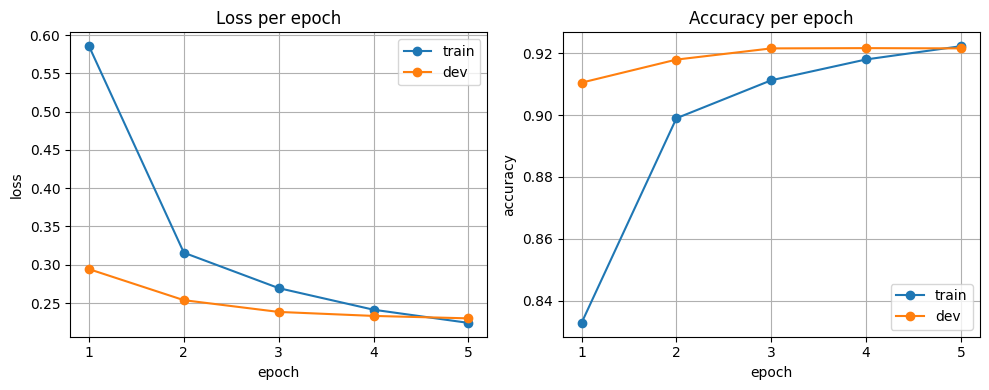

In [22]:
epochs = np.arange(n_epochs) + 1
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.plot(epochs, train_loss, marker='o', label='train')
ax1.plot(epochs, dev_loss, marker='o', label='dev')
ax1.set(xlabel='epoch', ylabel='loss', title='Loss per epoch')

ax2.plot(epochs, train_acc, marker='o', label='train')
ax2.plot(epochs, dev_acc, marker='o', label='dev')
ax2.set(xlabel='epoch', ylabel='accuracy', title='Accuracy per epoch')

for ax in (ax1, ax2):
    ax.set_xticks(epochs)
    ax.grid(True)
    ax.legend()
plt.tight_layout()
plt.show()

#### Observations (B.8)

- Development loss falls every epoch (0.294 to 0.230), with no clear evidence of
  worsening generalization during this five-epoch run.
- Development accuracy levels off at about 92.2% from epoch 3.
- Training accuracy trails development accuracy until epoch 5. Dropout is active during
  training, and each epoch average includes the early, weaker batches.

### B.9 Evaluating the model on the test set

The test set goes through the same preprocessing as the training set, with the vocabulary
built in B.6.

In [23]:
test_df = pd.read_csv(data_dir / 'test.csv')
test_df.columns = ['class index', 'title', 'description']
assert test_df.shape == (7600, 3)
assert set(test_df['class index'].unique()) == set(range(1, len(labels) + 1))
print('#NAME? cells in the test set:', (test_df[['title', 'description']] == '#NAME?').sum().sum())
test_df['text'] = join_fields(test_df).str.lower()
test_df['text'] = test_df['text'].replace(r'\\', ' ', regex=True)  # backslashes -> spaces
test_df['text'] = clean_html(test_df['text'])
test_df['tokens'] = test_df['text'].progress_map(word_tokenize)
test_df['features'] = test_df['tokens'].progress_map(make_feature_vector)
print(f'test rows: {len(test_df):,}')

#NAME? cells in the test set: 2


  0%|          | 0/7600 [00:00<?, ?it/s]

  0%|          | 0/7600 [00:00<?, ?it/s]

test rows: 7,600


In [24]:
from sklearn.metrics import classification_report

model.eval()
test_ds = BowDataset(test_df['features'], test_df['class index'] - 1)
test_dl = DataLoader(test_ds, batch_size=batch_size)

y_pred = []
with torch.no_grad():
    for X, _ in tqdm(test_dl, desc='test'):
        y_pred.append(model(X.to(device)).argmax(dim=1).cpu().numpy())

y_true = test_ds.y.to_numpy()
y_pred = np.concatenate(y_pred)
print(classification_report(y_true, y_pred, labels=range(len(labels)), target_names=labels, digits=4, zero_division=0))

test:   0%|          | 0/16 [00:00<?, ?it/s]

              precision    recall  f1-score   support

       World     0.9362    0.9042    0.9199      1900
      Sports     0.9581    0.9858    0.9717      1900
    Business     0.8917    0.8837    0.8877      1900
    Sci/Tech     0.8884    0.9011    0.8947      1900

    accuracy                         0.9187      7600
   macro avg     0.9186    0.9187    0.9185      7600
weighted avg     0.9186    0.9187    0.9185      7600



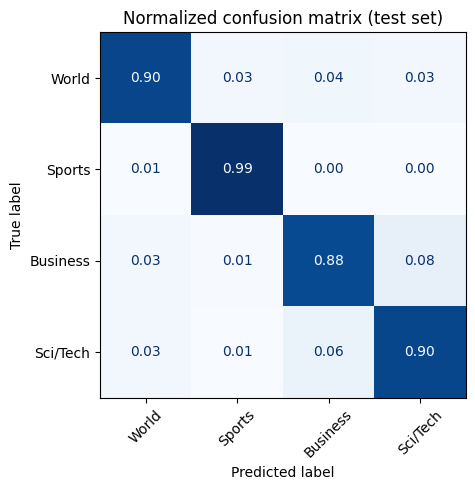

In [25]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(y_true, y_pred, normalize='true')
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
fig, ax = plt.subplots(figsize=(5, 5))
disp.plot(cmap='Blues', values_format='.2f', colorbar=False, ax=ax, xticks_rotation=45)
ax.set_title('Normalized confusion matrix (test set)')
plt.tight_layout()
plt.show()

In [26]:
# raw counts behind the normalized matrix
pd.DataFrame(confusion_matrix(y_true, y_pred), index=labels, columns=labels)

,World,Sports,Business,Sci/Tech
World,1718,54,73,55
Sports,13,1873,8,6
Business,52,15,1679,154
Sci/Tech,52,13,123,1712


In [27]:
# the first misclassified test articles, to see what kind of mistakes the model makes
errors = test_df.assign(gold=[labels[i] for i in y_true], predicted=[labels[i] for i in y_pred])
errors = errors[errors['gold'] != errors['predicted']]
print(f'misclassified: {len(errors):,} of {len(test_df):,}')
pd.set_option('display.max_colwidth', 120)
errors[['gold', 'predicted', 'title']].head(10)

misclassified: 618 of 7,600


,gold,predicted,title
13,Sci/Tech,World,Super ant colony hits Australia
20,Sci/Tech,Business,IBM to hire even more new workers
23,Sci/Tech,Business,Some People Not Eligible to Get in on Google IPO
24,Sci/Tech,Business,Rivals Try to Turn Tables on Charles Schwab
36,World,Business,Venezuela Prepares for Chavez Recall Vote
56,World,Business,India's Tata expands regional footprint via NatSteel buyout (AFP)
79,World,Sports,Live: Olympics day four
83,Business,Sci/Tech,Intel to delay product aimed for high-definition TVs
110,Business,Sci/Tech,Yahoo! Ups Ante for Small Businesses
120,World,Business,Oil prices bubble to record high


In [28]:
import hashlib
import json
import platform
from importlib.metadata import version

report = classification_report(
    y_true, y_pred, labels=range(len(labels)), target_names=labels,
    output_dict=True, zero_division=0,
)
cm_counts = confusion_matrix(y_true, y_pred, labels=range(len(labels)))
assert cm_counts.sum() == len(test_df)
assert (cm_counts.sum(axis=1) == 1900).all()
assert np.isclose(np.trace(cm_counts) / cm_counts.sum(), report['accuracy'])
assert len(token_to_id) == vocabulary_size
assert loss_func.weight is None

metrics = {
    'seed': seed,
    'device': str(device),
    'python': platform.python_version(),
    'versions': {name: version(name) for name in
                 ['torch', 'pandas', 'numpy', 'nltk', 'scikit-learn', 'tqdm', 'matplotlib']},
    'input_sha256': {name: hashlib.sha256((data_dir / name).read_bytes()).hexdigest()
                     for name in ['train.csv', 'test.csv', 'classes.txt']},
    'train_rows': len(train_df), 'development_rows': len(dev_df), 'test_rows': len(test_df),
    'vocabulary_size': vocabulary_size, 'distinct_training_tokens': distinct_token_count,
    'total_training_tokens': total_token_occurrences,
    'retained_training_tokens': retained_token_occurrences,
    'trainable_parameters': n_params,
    'hyperparameters': {'learning_rate': lr, 'weight_decay': weight_decay,
                        'batch_size': batch_size, 'epochs': n_epochs,
                        'hidden_units': hidden_dim, 'dropout': dropout},
    'classification_report': report,
    'confusion_matrix': cm_counts.tolist(), 'class_order': labels,
    'history': {'train_loss': train_loss, 'train_accuracy': train_acc,
                'development_loss': dev_loss, 'development_accuracy': dev_acc},
    'elapsed_seconds': time.perf_counter() - run_started,
}
artifacts_dir = Path('artifacts')
artifacts_dir.mkdir(exist_ok=True)
(artifacts_dir / 'metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
print(f"Verified: {np.trace(cm_counts):,}/{len(test_df):,} correct; "
      f"accuracy {report['accuracy']:.4%}; macro F1 {report['macro avg']['f1-score']:.4f}")
print('Saved artifacts/metrics.json with input hashes, versions, and measured results.')

Verified: 6,982/7,600 correct; accuracy 91.8684%; macro F1 0.9185
Saved artifacts/metrics.json with input hashes, versions, and measured results.


#### Observations (B.9)

- Test accuracy is 91.87% (618 errors), close to development (92.16%) and the reference (0.92).
- Sports is easiest (F1 0.972); Business is hardest (0.888).
- The largest confusion: 154 Business articles predicted as Sci/Tech, 123 the reverse.
- Several errors involve technology companies such as IBM, Google, Intel, and Yahoo!

---
## Part C: Analysis

### C.1 How the commands in Part B work

#### B.1 Initialization

`tqdm.pandas()` registers pandas progress methods: `Series.progress_map()` maps a function
with a progress bar, and `progress_apply()` supports apply operations on Series and DataFrames.
`tqdm.auto` chooses a suitable notebook or terminal display (tqdm developers, n.d.).
`torch.device` selects CUDA when available; this run uses the CPU. Python, NumPy, and PyTorch
are seeded with 1234. These seeds control random generators but cannot guarantee identical
outputs across PyTorch releases, hardware, or all operations (PyTorch, n.d.).

#### B.2 Dataset files

`Path.stat().st_size` checks file sizes. `read_text().splitlines()` loads the four class
names from `classes.txt`; class index 1 corresponds to the first line. Labels must remain
in that order so that reports describe the correct output classes.

#### B.3 Loading and examining the data

`pd.read_csv()` reads the header in the local files; assigning `columns` standardizes names.
Assertions check expected dimensions and label values. The reference notebook uses
`header=None` for its headerless release; using that option here would incorrectly treat the
header as an extra data row. `insert` and `map` add readable class names. `info()`,
`isna().sum()`, `value_counts()`, and `duplicated()` check types, missingness, balance, and
exact duplicate text pairs. `str.split().str.len()` and `describe()` summarize field lengths.
`str.contains()` counts selected noise patterns (The pandas development team, n.d.).

The observed 30,000 examples per class support a 25% uniform-random or majority-class
baseline. The median headline has seven whitespace-separated words and the median summary
has thirty. No pandas missing values were found, but the literal `#NAME?` values represent
corrupted text; absence of nulls does not establish data quality.

#### B.4 Backslashes and other cleaning

`join_fields()` replaces entire `#NAME?` cells with empty strings and concatenates the
remaining title and description. Lowercasing merges capitalization variants.
`Series.replace(r'\\', ' ', regex=True)` replaces backslashes inside every string.
The raw regular expression `r'\\'` matches one literal backslash. This directly uses the
pandas `replace` method requested in the assignment; `str.replace('\\', ' ', regex=False)`
is an equivalent literal-string alternative. The post-cleaning count confirms zero
backslashes remain.

`clean_html()` repairs selected incomplete character references, decodes them with
`html.unescape()`, removes tags and URLs, and normalizes whitespace. Decoding runs twice for
double escaping. These deterministic rules are identical for every split. Zero counts for
the selected patterns confirm their removal, but do not prove that all conceivable noise is
gone. URL removal may also discard useful signals; its benefit was not tested in an ablation.

#### B.5 Tokenization and development split

`word_tokenize()` combines word tokenization with sentence segmentation and separates
punctuation and contractions (Bird et al., 2009). The `punkt_tab` resources are downloaded
only if absent. `progress_map` stores each token list in `tokens`.
`train_test_split(..., train_size=0.8, random_state=seed)` creates 96,000 fitting examples and
24,000 development examples. The split is random without stratification; printed development
class shares are approximately 24.8% to 25.4%. `reset_index(drop=True)` resets row labels.
Only the fitting split supplies vocabulary statistics, preventing vocabulary leakage.

#### B.6 Vocabulary and features

`explode().value_counts()` counts training tokens. Filtering with `> 10` retains 17,368
individual tokens; `[UNK]` adds one feature, making 17,369 dimensions. The retained tokens
cover 3,856,145 of 4,010,277 training token occurrences (96.2%). These totals are printed in
B.6. `token_to_id` and `id_to_token` map between strings and identifiers.
`make_feature_vector()` increments a sparse dictionary of raw counts, mapping rare or unseen
tokens to index zero. Counts preserve frequency, not word order; no TF-IDF weighting is used.

#### B.7 Model, loss, optimizer, and data loaders

`BowDataset.__getitem__()` expands one sparse dictionary into a float32 vector and returns
its zero-based `torch.long` label. `.iloc` selects rows by position. Constructing vectors on
demand avoids storing approximately 6.67 GB of dense training features
(96,000 × 17,369 × 4 bytes), excluding overhead. A full batch alone uses about 34.7 MB.

`nn.Sequential` chains input dropout, `Linear(17369, 50)`, ReLU, hidden dropout, and
`Linear(50, 4)`. The network has 868,704 parameters; 868,500 are in its first linear layer.
`CrossEntropyLoss` accepts raw logits and integer class indices and combines log-softmax
with negative log-likelihood, so no extra softmax is applied (PyTorch, n.d.).
`Adam(..., lr=0.001, weight_decay=0.00001)` updates parameters with L2 regularization in this
configuration. Dropout is 0.3. The training loader shuffles 192 batches of 500; development
and test loaders preserve order. Hyperparameters follow the reference notebook without tuning.

#### B.8 Training

`model.train()` activates dropout. Each batch clears old gradients with `model.zero_grad()`,
computes logits and cross-entropy, calls `loss.backward()`, and updates weights with
`optimizer.step()`. Training loss and accuracy average observations while weights change.
`model.eval()` disables dropout for development; `torch.no_grad()` disables gradient
tracking. Each epoch records development metrics without learning from development labels.

Averaging batch means is exact here because 96,000 and 24,000 are divisible by 500. If batch
sizes differed, loss and accuracy should instead be weighted by batch size. Training and
development values are not directly comparable because dropout and parameter updates are
active only during training. Five epochs were specified in advance; the final epoch model
is evaluated without selecting settings from test performance.

#### B.9 Evaluation

The test file receives the same cleaning and tokenization, then the fixed training vocabulary.
Unseen words map to `[UNK]`. In evaluation mode without gradients, `argmax(dim=1)` selects
one class per article. `classification_report()` calculates precision, recall, F1, and
accuracy. Precision measures how many predictions of a class are correct; recall measures
how many actual members of that class are recovered. F1 is their harmonic mean,
`2 * precision * recall / (precision + recall)` (Pedregosa et al., 2011).

The raw confusion matrix uses true labels as rows and predicted labels as columns.
`normalize='true'` divides each row by its support, making the diagonal equal class recall.
For example, World recall is 1,718 / 1,900 = 0.9042. The error table provides concrete examples.
A final verification cell saves metrics, class supports, package versions, and input hashes.

### C.2 Interpreting the evaluation results

#### Overall performance

The model correctly classifies 6,982 of 7,600 test articles: **91.87% accuracy**, with 618
errors and macro F1 **0.9185**. Each class has 1,900 examples, so support-weighted and macro
precision, recall, and F1 are mathematically equal before display rounding. Both summarize
all four topics equally in this balanced test set. Accuracy substantially exceeds the 25%
baseline. The reference notebook reports rounded accuracy 0.92 and similar per-class F1
scores. This is consistent with its reported performance, but rounded agreement does not
establish exact reproduction, particularly with different cleaning and dataset variants.

| Class | Precision | Recall | F1 | Errors out of 1,900 |
|---|---|---|---|---|
| World | 0.9362 | 0.9042 | 0.9199 | 182 |
| Sports | 0.9581 | 0.9858 | 0.9717 | 27 |
| Business | 0.8917 | 0.8837 | 0.8877 | 221 |
| Sci/Tech | 0.8884 | 0.9011 | 0.8947 | 188 |

#### Error patterns

Sports has the highest F1 (0.9717), with 1,873 correct predictions. Distinctive names and
competition vocabulary are a plausible explanation, although this run does not measure
feature importance or establish that cause.

World precision (0.9362) exceeds its recall (0.9042): relatively few predicted World articles
are wrong, but 182 World articles are missed. Of these, 73 are predicted Business, 55 Sci/Tech,
and 54 Sports. Titles such as the Tata buyout and Olympic coverage illustrate overlapping
topic vocabulary.

The largest confusion is between Business and Sci/Tech: 154 Business articles are predicted
Sci/Tech, and 123 Sci/Tech articles are predicted Business. These 277 mistakes account for
44.8% of all errors. The IBM hiring and Google IPO headlines are labeled Sci/Tech, while
Intel product delays and Yahoo small-business headlines are labeled Business. Such stories
share company names and commercial vocabulary. Bag-of-words features discard word order,
which may contribute to ambiguity; the confusion matrix alone cannot establish the main
cause of the errors. Label ambiguity and short texts may also contribute.

#### Learning behavior and limitations

Training loss decreases from 0.5856 to 0.2241, and development loss decreases from 0.2943 to
0.2300. There is no clear evidence of worsening development loss over these five epochs;
this does not prove the absence of overfitting or predict what a longer run would do.
Development accuracy plateaus near 92.2% from epoch three. Final development accuracy is
92.16%, about 0.29 percentage points above test accuracy. This shows close agreement on
these splits, without guaranteeing performance on future or differently sourced news.

Training accuracy is initially lower than development accuracy because dropout is active
and the epoch average includes predictions made before later updates. The figures come
from one seed and one fixed test set. Run-to-run variability was not measured, so small
score differences should not be overinterpreted. Data corruption and the loss of word order
limit the method. Bigrams, embeddings, or sequence models are possible follow-up experiments;
their benefit would need separate development-set evaluation (Jurafsky & Martin, 2026).


---
## References

Anand, A. (2020). *AG News Classification Dataset* [Data set]. Kaggle.
https://www.kaggle.com/datasets/amananandrai/ag-news-classification-dataset

Bird, S., Klein, E., & Loper, E. (2009). *Natural language processing with Python*. O'Reilly
Media. NLTK `word_tokenize` documentation: https://www.nltk.org/api/nltk.tokenize.word_tokenize.html

Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep learning*. MIT Press.
https://www.deeplearningbook.org/

Jurafsky, D., & Martin, J. H. (2026). *Speech and language processing* (3rd ed. draft,
August 19, 2026 release). https://web.stanford.edu/~jurafsky/slp3/

Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. *International
Conference on Learning Representations*. https://arxiv.org/abs/1412.6980

Microsoft. (n.d.). *How to correct a #NAME? error*. Microsoft Support.
https://support.microsoft.com/en-us/office/how-to-correct-a-name-error-b6d54e31-a743-4d7d-9b61-40002a7b4286

Nair, V., & Hinton, G. E. (2010). Rectified linear units improve restricted Boltzmann
machines. *Proceedings of the 27th International Conference on Machine Learning*, 807–814.

Paszke, A., Gross, S., Massa, F., et al. (2019). PyTorch: An imperative style,
high-performance deep learning library. *Advances in Neural Information Processing Systems,
32*. Documentation used: `torch.nn.CrossEntropyLoss`, `torch.optim.Adam`, and
`torch.utils.data`, https://pytorch.org/docs/stable/

Pedregosa, F., Varoquaux, G., Gramfort, A., et al. (2011). Scikit-learn: Machine learning in
Python. *Journal of Machine Learning Research, 12*, 2825–2830.
https://jmlr.org/papers/v12/pedregosa11a.html

PyTorch. (n.d.). *CrossEntropyLoss* and *Reproducibility* [Documentation].
https://docs.pytorch.org/docs/2.14/generated/torch.nn.CrossEntropyLoss.html
https://docs.pytorch.org/docs/2.14/notes/randomness.html

Python Software Foundation. (n.d.). *html: HyperText Markup Language support* (`html.unescape`).
https://docs.python.org/3/library/html.html

Rumelhart, D. E., Hinton, G. E., & Williams, R. J. (1986). Learning representations by
back-propagating errors. *Nature, 323*, 533–536.

Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., & Salakhutdinov, R. (2014).
Dropout: A simple way to prevent neural networks from overfitting. *Journal of Machine
Learning Research, 15*, 1929–1958. https://jmlr.org/papers/v15/srivastava14a.html

Surdeanu, M., & Valenzuela-Escárcega, M. A. (2023). *Deep learning for natural language
processing: A gentle introduction*. Cambridge University Press. Chapter 7 notebook:
https://github.com/clulab/gentlenlp/blob/main/notebooks/chap07_ffnn.ipynb

The pandas development team. (n.d.). *pandas documentation* (`read_csv`, `Series.replace`).
https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html
https://pandas.pydata.org/docs/reference/api/pandas.Series.replace.html

tqdm developers. (n.d.). *tqdm documentation* (pandas integration). https://github.com/tqdm/tqdm

Zhang, X., Zhao, J., & LeCun, Y. (2015). Character-level convolutional networks for text
classification. *Advances in Neural Information Processing Systems, 28*.
https://proceedings.neurips.cc/paper/2015/hash/250cf8b51c773f3f8dc8b4be867a9a02-Abstract.html
Original data files (including `classes.txt`): https://s3.amazonaws.com/fast-ai-nlp/ag_news_csv.tgz